# Classification: Predicting Late Delivery Risk
# Phân loại: Dự đoán rủi ro giao hàng trễ

**EN:** This notebook is the main analysis of the thesis on the DataCo Smart Supply Chain dataset. Stage 1 (Power BI) showed that more than half of the orders are delivered late. Here we ask: *can we predict, at the moment an order is placed, whether it will be delivered late?* The notebook follows the MIS 451 classification workflow: load data → partition → EDA → transformation → model development → comparison → final model.

**VI:** Notebook này là phần phân tích chính của luận văn trên bộ dữ liệu DataCo. Ở Stage 1 (Power BI), hơn một nửa số đơn bị giao trễ. Câu hỏi ở đây là: *có thể dự đoán ngay lúc đặt hàng xem đơn đó có bị giao trễ hay không?* Notebook đi theo quy trình classification của môn MIS 451: đọc dữ liệu → chia dữ liệu → EDA → biến đổi dữ liệu → xây model → so sánh → model cuối.

In [50]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import logging
logging.basicConfig()
logging.getLogger("SKLEARNEX").setLevel(logging.ERROR)

import warnings
warnings.filterwarnings("ignore")

# Data Preprocessing
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Data Partitioning and Cross-validation
from sklearn.model_selection import GroupShuffleSplit, GroupKFold, GridSearchCV, cross_val_score

# Machine Learning
from sklearn.dummy import DummyClassifier
from sklearn.tree import DecisionTreeClassifier, export_text, plot_tree
from sklearn.linear_model import LogisticRegression

# Metrics
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score, roc_auc_score
from sklearn.metrics import classification_report, confusion_matrix

np.random.seed(42)

# **1. Load the data**

In [51]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [52]:
file_path = '/content/drive/MyDrive/BUS_450/clean_supply_chain.csv'

In [53]:
df = pd.read_csv(file_path)

**EN:** Each row is one *order item*. The target is `late_delivery_risk`: **0 = delivered on time, 1 = delivered late**. We use the **full dataset** (180,519 rows, January 2015 to January 2018). From October 2017 the order pattern changes (about one item per order and few products), which is noted in the limitations. The check below confirms that all items of one order share the same delivery result (maximum = 1), so the label is really a property of the order.

**VI:** Mỗi dòng là một *mặt hàng trong đơn*. Biến mục tiêu là `late_delivery_risk`: **0 = giao đúng hạn, 1 = giao trễ**. Ta dùng **toàn bộ dataset** (180,519 dòng, từ 01/2015 đến 01/2018). Từ tháng 10/2017 mô hình đơn hàng thay đổi (khoảng một mặt hàng mỗi đơn và ít sản phẩm), điều này được ghi trong phần hạn chế. Kiểm tra bên dưới xác nhận mọi mặt hàng trong cùng một đơn có cùng kết quả giao hàng (giá trị lớn nhất = 1), nên nhãn thực chất là thuộc tính của cả đơn.

In [54]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 180519 entries, 0 to 180518
Data columns (total 48 columns):
 #   Column                       Non-Null Count   Dtype  
---  ------                       --------------   -----  
 0   type                         180519 non-null  object 
 1   days_for_shipping_real       180519 non-null  int64  
 2   days_for_shipment_scheduled  180519 non-null  int64  
 3   benefit_per_order            180519 non-null  float64
 4   sales_per_customer           180519 non-null  float64
 5   delivery_status              180519 non-null  object 
 6   late_delivery_risk           180519 non-null  int64  
 7   category_id                  180519 non-null  int64  
 8   category_name                180519 non-null  object 
 9   customer_city                180519 non-null  object 
 10  customer_country             180519 non-null  object 
 11  customer_id                  180519 non-null  int64  
 12  customer_segment             180519 non-null  object 
 13 

In [55]:
df.head()

,type,days_for_shipping_real,days_for_shipment_scheduled,benefit_per_order,sales_per_customer,delivery_status,late_delivery_risk,category_id,category_name,customer_city,...,product_category_id,product_name,product_price,product_status,shipping_mode,order_date,shipping_date,shipping_delay,order_month,is_late
0,DEBIT,3,4,91.250000,314.640015,Advance shipping,0,73,Sporting Goods,Caguas,...,73,Smart watch,327.75,0,Standard Class,2018-01-31 22:56:00,2018-02-03 22:56:00,-1,2018-01,False
1,TRANSFER,5,4,-249.089996,311.359985,Late delivery,1,73,Sporting Goods,Caguas,...,73,Smart watch,327.75,0,Standard Class,2018-01-13 12:27:00,2018-01-18 12:27:00,1,2018-01,True
2,CASH,4,4,-247.779999,309.720001,Shipping on time,0,73,Sporting Goods,San Jose,...,73,Smart watch,327.75,0,Standard Class,2018-01-13 12:06:00,2018-01-17 12:06:00,0,2018-01,False
3,DEBIT,3,4,22.860001,304.809998,Advance shipping,0,73,Sporting Goods,Los Angeles,...,73,Smart watch,327.75,0,Standard Class,2018-01-13 11:45:00,2018-01-16 11:45:00,-1,2018-01,False
4,PAYMENT,2,4,134.210007,298.250000,Advance shipping,0,73,Sporting Goods,Caguas,...,73,Smart watch,327.75,0,Standard Class,2018-01-13 11:24:00,2018-01-15 11:24:00,-2,2018-01,False


In [56]:
df.duplicated().sum()

np.int64(0)

In [57]:
df.isnull().sum()

,0
type,0
days_for_shipping_real,0
days_for_shipment_scheduled,0
benefit_per_order,0
sales_per_customer,0
delivery_status,0
late_delivery_risk,0
category_id,0
category_name,0
customer_city,0


In [58]:
df["order_date"] = pd.to_datetime(df["order_date"])
df["order_date"].dtype

dtype('<M8[ns]')

In [59]:
data = df.copy()
data.shape

(180519, 48)

In [60]:
data.groupby("order_id")["late_delivery_risk"].nunique().max()

1

In [61]:
data["late_delivery_risk"].value_counts(normalize=True)

,proportion
late_delivery_risk,
1,0.548291
0,0.451709


**EN:** 54.8% of the orders are late and 45.2% are on time, so the classes are fairly balanced. A trivial rule "always predict late" is already 54.8% accurate. This is the minimum that any useful model has to beat.

**VI:** 54.8% số đơn bị trễ và 45.2% đúng hạn, nên hai lớp khá cân bằng. Một quy tắc đơn giản "luôn đoán là trễ" đã đúng 54.8%. Đây là mức tối thiểu mà một model hữu ích phải vượt qua.

# **2. Data Partitioning**

**EN:** One order can contain several items, and all of them have the same delivery result. If we split the data randomly by row, items of the same order would appear in both the training and the test set. The model would then "see" part of the test orders during training and the test score would look better than it really is. Therefore the data are split **by Order ID**: 80% of the orders for training (144,683 rows) and 20% for testing (35,836 rows). The check below confirms that no order appears in both sets. Cross-validation inside the training set is also grouped by order (`GroupKFold`).

**VI:** Một đơn có thể có nhiều mặt hàng và tất cả đều có cùng kết quả giao hàng. Nếu chia ngẫu nhiên theo dòng, các mặt hàng của cùng một đơn sẽ nằm ở cả tập train lẫn test. Khi đó model đã "nhìn thấy" một phần đơn của tập test lúc học, nên điểm test đẹp hơn thực tế. Vì vậy dữ liệu được chia **theo Order ID**: 80% số đơn để train (144,683 dòng) và 20% để test (35,836 dòng). Kiểm tra bên dưới xác nhận không có đơn nào nằm ở cả hai tập. Cross-validation trong tập train cũng được chia theo đơn (`GroupKFold`).

In [62]:
gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=99)
train_idx, test_idx = next(gss.split(data, groups=data["order_id"]))

In [63]:
train = data.iloc[train_idx].reset_index(drop=True)
test = data.iloc[test_idx].reset_index(drop=True)

In [64]:
train.shape, test.shape

((144683, 48), (35836, 48))

In [65]:
# No order appears in both sets
len(set(train["order_id"]) & set(test["order_id"]))

0

In [66]:
train["late_delivery_risk"].value_counts(normalize=True)

,proportion
late_delivery_risk,
1,0.547811
0,0.452189


In [67]:
print(train["order_date"].dtype, "|", test["order_date"].dtype)
print(data["order_date"].min(), "→", data["order_date"].max())
data.shape, train.shape, test.shape

datetime64[ns] | datetime64[ns]
2015-01-01 00:00:00 → 2018-01-31 23:38:00


((180519, 48), (144683, 48), (35836, 48))

# **3. Exploratory Data Analysis**

**EN:** The model is meant to estimate the risk of a late delivery **when the order is placed**, so we only use information that is known at that moment:

- **Used:** shipping mode, payment type, customer segment, market, order region, product category, department, scheduled shipping days, quantity, product price, discount, discount rate, order month.
- **Not used (data leakage):** `days_for_shipping_real`, `shipping_delay`, `shipping_date`, `delivery_status`, `is_late`, `order_status`. These columns describe what happened during or after the delivery. With them the model would only "discover" that an order is late because the data already say it is late.

**VI:** Model dùng để ước lượng rủi ro giao trễ **ngay lúc đặt hàng**, nên chỉ dùng thông tin đã biết ở thời điểm đó:

- **Dùng:** shipping mode, loại thanh toán, customer segment, market, vùng đặt hàng, nhóm sản phẩm, department, số ngày giao dự kiến, số lượng, giá sản phẩm, discount, tỉ lệ discount, tháng đặt hàng.
- **Không dùng (rò rỉ dữ liệu):** `days_for_shipping_real`, `shipping_delay`, `shipping_date`, `delivery_status`, `is_late`, `order_status`. Các cột này mô tả những gì xảy ra trong hoặc sau khi giao hàng. Nếu dùng, model chỉ "phát hiện" đơn trễ vì dữ liệu đã cho biết đơn đó trễ.

In [68]:
# Variables known when the order is placed (no information from the delivery itself)
cat_cols = ["shipping_mode", "type", "customer_segment", "market",
            "order_region", "category_name", "department_name"]
num_cols = ["days_for_shipment_scheduled", "order_item_quantity", "order_item_product_price",
            "order_item_discount", "order_item_discount_rate", "order_month_num"]

train["order_month_num"] = train["order_date"].dt.month
test["order_month_num"] = test["order_date"].dt.month

target = "late_delivery_risk"

In [69]:
train[cat_cols + num_cols].info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 144683 entries, 0 to 144682
Data columns (total 13 columns):
 #   Column                       Non-Null Count   Dtype  
---  ------                       --------------   -----  
 0   shipping_mode                144683 non-null  object 
 1   type                         144683 non-null  object 
 2   customer_segment             144683 non-null  object 
 3   market                       144683 non-null  object 
 4   order_region                 144683 non-null  object 
 5   category_name                144683 non-null  object 
 6   department_name              144683 non-null  object 
 7   days_for_shipment_scheduled  144683 non-null  int64  
 8   order_item_quantity          144683 non-null  int64  
 9   order_item_product_price     144683 non-null  float64
 10  order_item_discount          144683 non-null  float64
 11  order_item_discount_rate     144683 non-null  float64
 12  order_month_num              144683 non-null  int32  
dtyp

In [70]:
train[cat_cols + num_cols].isnull().sum()

,0
shipping_mode,0
type,0
customer_segment,0
market,0
order_region,0
category_name,0
department_name,0
days_for_shipment_scheduled,0
order_item_quantity,0
order_item_product_price,0


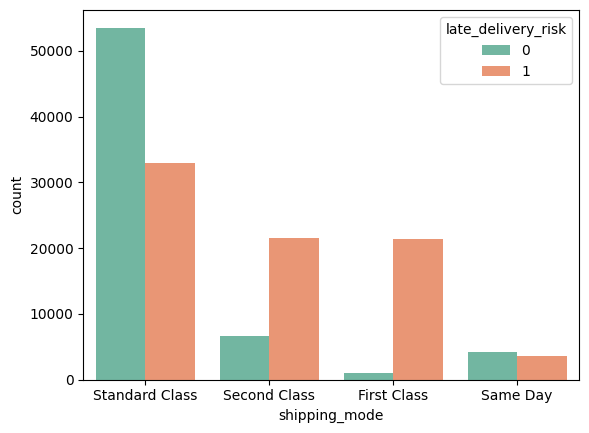

In [71]:
# Late rate by shipping mode (same style as the classification notebook)
sns.countplot(train, x="shipping_mode", hue=target, palette="Set2")
plt.show()

In [72]:
# Late rate (%) by shipping mode
(pd.crosstab(train["shipping_mode"], train[target], normalize="index") * 100).round(1)

late_delivery_risk,0,1
shipping_mode,,
First Class,4.7,95.3
Same Day,54.2,45.8
Second Class,23.6,76.4
Standard Class,61.9,38.1


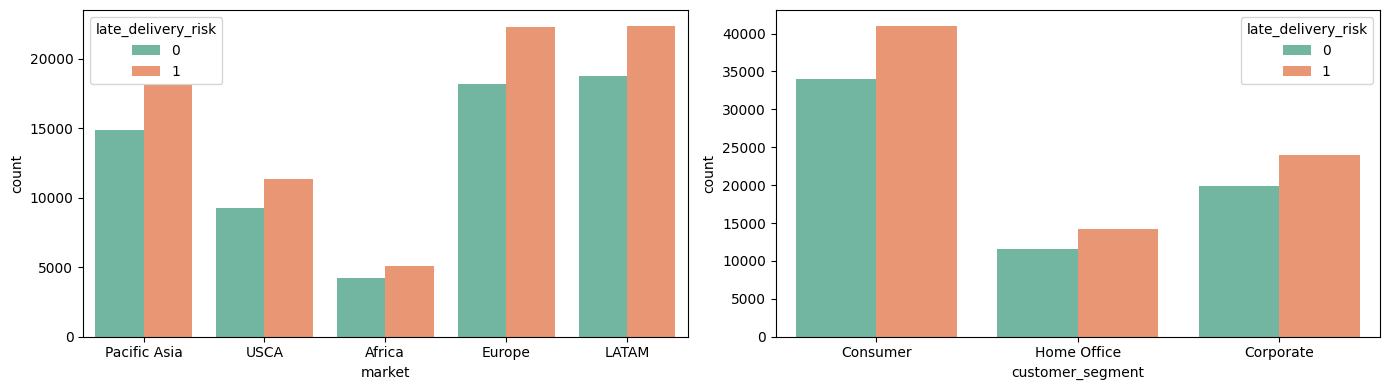

In [73]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.countplot(train, x="market", hue=target, palette="Set2", ax=axes[0])
sns.countplot(train, x="customer_segment", hue=target, palette="Set2", ax=axes[1])
plt.tight_layout()
plt.show()

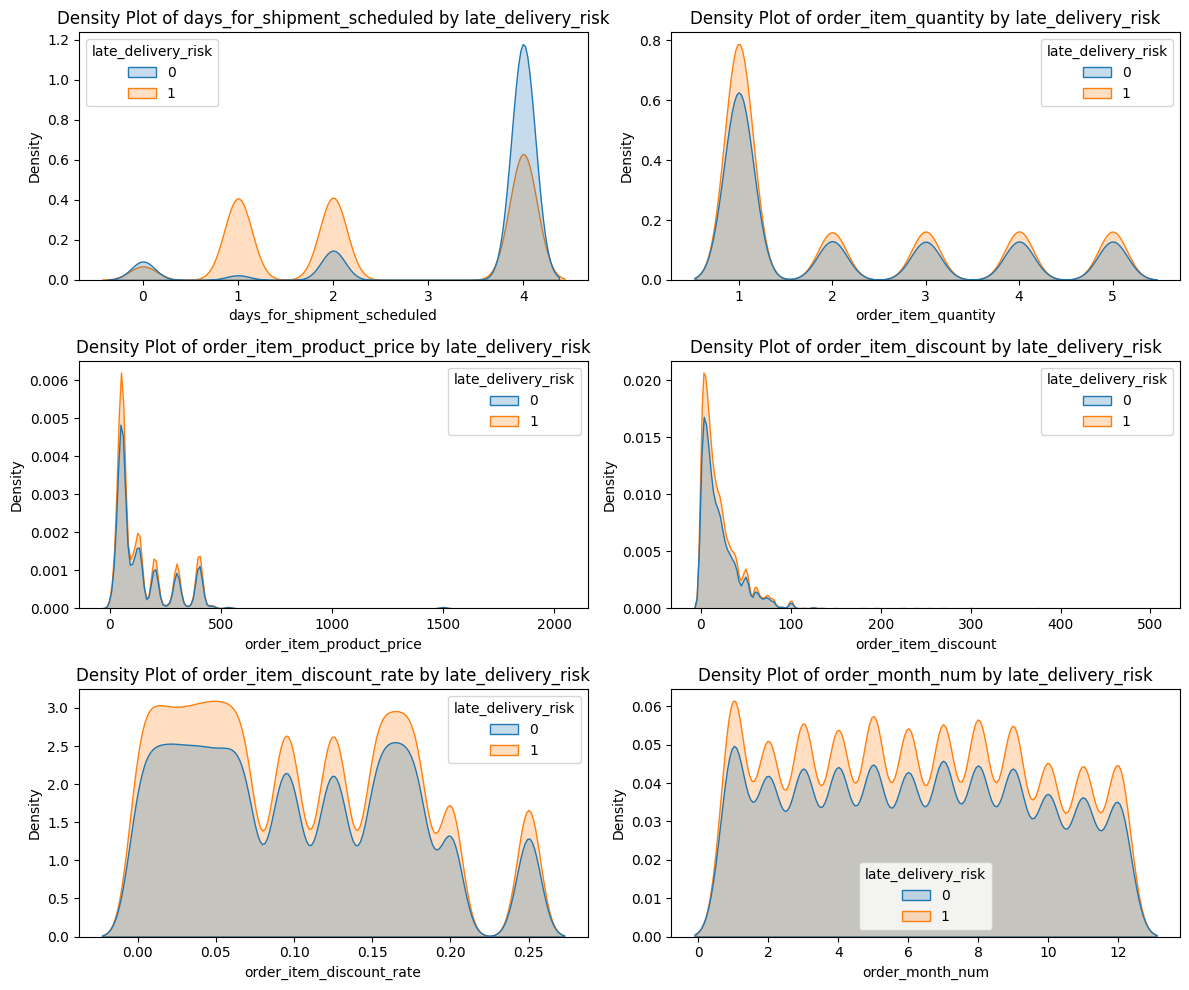

In [74]:
plt.figure(figsize=(12, 10))
for i, col in enumerate(num_cols, 1):
    plt.subplot(3, 2, i)
    sns.kdeplot(data=train, x=col, hue=target, fill=True)
    plt.title(f"Density Plot of {col} by {target}", fontsize=12)
plt.tight_layout()
plt.show()

In [75]:
# Late rate (%) by scheduled shipping days
(pd.crosstab(train["days_for_shipment_scheduled"], train[target], normalize="index") * 100).round(1)

late_delivery_risk,0,1
days_for_shipment_scheduled,,
0,54.2,45.8
1,4.7,95.3
2,23.6,76.4
4,61.9,38.1


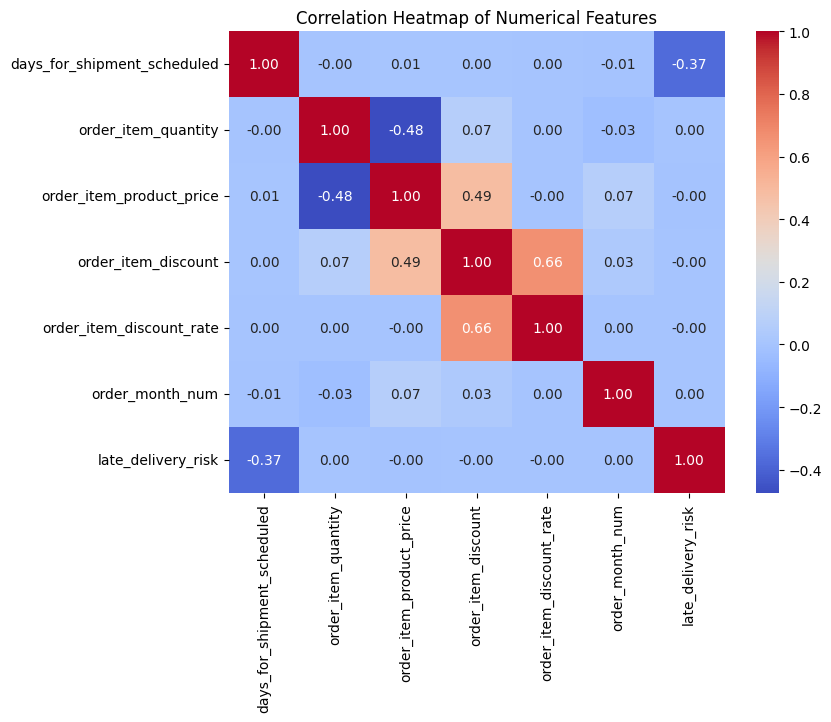

In [76]:
plt.figure(figsize=(8, 6))
sns.heatmap(train[num_cols + [target]].corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap of Numerical Features")
plt.show()

**EN – Findings:**
- **Shipping mode is the strongest signal.** In the training set the late rate is 95.3% for First Class, 76.4% for Second Class, 45.8% for Same Day and 38.1% for Standard Class.
- **Scheduled shipping days gives exactly the same rates** (1 day = 95.3%, 2 days = 76.4%, 0 days = 45.8%, 4 days = 38.1%). So it carries the same information as shipping mode: each mode has one promised delivery time.
- The faster (and more expensive) modes are late more often. A possible explanation is that the promised delivery time of these modes is too tight; this should be discussed together with the Stage 1 results.
- The other variables are much less informative. In every market and customer segment late orders are the larger group, with similar proportions. For quantity, product price and discount the density curves of the two classes almost overlap.

**VI – Nhận xét:**
- **Shipping mode là tín hiệu mạnh nhất.** Trong tập train, tỉ lệ trễ là 95.3% với First Class, 76.4% với Second Class, 45.8% với Same Day và 38.1% với Standard Class.
- **Số ngày giao dự kiến cho đúng cùng các tỉ lệ đó** (1 ngày = 95.3%, 2 ngày = 76.4%, 0 ngày = 45.8%, 4 ngày = 38.1%). Nghĩa là nó mang cùng thông tin với shipping mode: mỗi mode có một thời gian giao đã hứa.
- Các mode nhanh hơn (và đắt hơn) lại trễ nhiều hơn. Một lời giải thích có thể là thời gian giao hứa cho các mode này quá chặt; nên đối chiếu với kết quả Stage 1.
- Các biến còn lại ít thông tin hơn nhiều. Ở mọi market và customer segment, đơn trễ đều chiếm nhiều hơn với tỉ lệ tương tự nhau. Với số lượng, giá sản phẩm và discount, đường mật độ của hai lớp gần như chồng lên nhau.

# **4. Data Transformation**

**EN:** Models need numbers, so the 7 categorical variables are converted by **one-hot encoding** (each category becomes a 0/1 column, which gives 106 columns in total together with the 6 numerical variables). The variables are **standardised** so that they have a comparable scale; this matters for Logistic Regression, while the Decision Tree does not need it and uses the original values. The encoder and the scaler are fitted on the **training set only** and then applied to the test set, so that no information from the test set leaks into training.

**VI:** Model cần dữ liệu dạng số, nên 7 biến phân loại được chuyển bằng **one-hot encoding** (mỗi nhóm thành một cột 0/1, cùng với 6 biến số, tổng cộng 106 cột). Các biến được **chuẩn hóa** để có cùng thang đo; điều này quan trọng với Logistic Regression, còn Decision Tree không cần và dùng giá trị gốc. Encoder và scaler chỉ được fit trên **tập train** rồi mới áp dụng cho tập test, để thông tin của tập test không lọt vào quá trình học.

In [77]:
one_hot_encoder = OneHotEncoder(sparse_output=False, handle_unknown="ignore")

transformed = one_hot_encoder.fit_transform(train[cat_cols])       # fit on train only
new_col_names = one_hot_encoder.get_feature_names_out(cat_cols)

Xtrain = pd.concat([train[num_cols], pd.DataFrame(transformed, columns=new_col_names)], axis=1)
Xtest = pd.concat([test[num_cols],
                   pd.DataFrame(one_hot_encoder.transform(test[cat_cols]), columns=new_col_names)], axis=1)

ytrain = train[target].copy()
ytest = test[target].copy()

Xtrain.shape, Xtest.shape

((144683, 106), (35836, 106))

In [78]:
feature_names = Xtrain.columns
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(Xtrain)
X_test_scaled = scaler.transform(Xtest)

Xtrain, Xtest = X_train_scaled, X_test_scaled
groups_train = train["order_id"]

# **5. Model Development**

**EN:** Two simple models from the course are compared: Logistic Regression and a Decision Tree. Metrics:

- **Accuracy:** share of correct predictions.
- **F1 (macro):** average F1 of the two classes; our main metric because it treats late and on-time orders equally.
- **Precision (Late):** when the model says "late", how often it is right.
- **Recall (Late):** of all orders that are really late, how many the model finds.
- **ROC-AUC:** how well the model ranks late orders above on-time orders (0.5 = guessing, 1 = perfect).

Models are **chosen** with grouped cross-validation on the training set (F1 macro) and **confirmed once** on the test set. Both models use the whole training set.

**VI:** So sánh hai model đơn giản trong môn học: Logistic Regression và Decision Tree. Các chỉ số:

- **Accuracy:** tỉ lệ dự đoán đúng.
- **F1 (macro):** trung bình F1 của hai lớp; là chỉ số chính vì xem đơn trễ và đơn đúng hạn ngang nhau.
- **Precision (Late):** khi model nói "trễ" thì đúng bao nhiêu phần.
- **Recall (Late):** trong các đơn thật sự trễ, model tìm ra được bao nhiêu.
- **ROC-AUC:** khả năng xếp đơn trễ cao hơn đơn đúng hạn (0.5 = đoán mò, 1 = hoàn hảo).

Model được **chọn** bằng cross-validation theo nhóm đơn trên tập train (F1 macro) và **xác nhận một lần** trên tập test. Cả hai model đều dùng toàn bộ tập train.

In [79]:
results_clf = {}

def score_classifier(name, y_true, y_pred, y_score):
    results_clf[name] = {
        "Accuracy": accuracy_score(y_true, y_pred),
        "F1 (macro)": f1_score(y_true, y_pred, average="macro"),
        "Precision (Late)": precision_score(y_true, y_pred),
        "Recall (Late)": recall_score(y_true, y_pred),
        "ROC-AUC": roc_auc_score(y_true, y_score)
    }

gkf = GroupKFold(n_splits=5)

**5.0 Baseline**

**EN:** Two baselines give a reference point. (1) *Majority class*: always predict "late" (on the test set: accuracy 55.0%, F1 macro 0.355). (2) *Shipping mode only*: a logistic regression that uses nothing but shipping mode. It tests whether the other variables add anything beyond what shipping mode already explains.

**VI:** Hai baseline làm mốc so sánh. (1) *Majority class*: luôn đoán "trễ" (trên tập test: accuracy 55.0%, F1 macro 0.355). (2) *Chỉ dùng shipping mode*: một logistic regression chỉ có shipping mode. Baseline này kiểm tra xem các biến còn lại có thêm được gì so với những gì shipping mode đã giải thích.

In [80]:
dummy = DummyClassifier(strategy="most_frequent").fit(Xtrain, ytrain)
score_classifier("Baseline (majority class)", ytest, dummy.predict(Xtest), np.full(len(ytest), 0.5))

In [81]:
sm_cols = [i for i, c in enumerate(feature_names) if c.startswith("shipping_mode_")]
lr_base = LogisticRegression().fit(Xtrain[:, sm_cols], ytrain)
score_classifier("Baseline 2 (shipping mode only)", ytest, lr_base.predict(Xtest[:, sm_cols]),
                 lr_base.predict_proba(Xtest[:, sm_cols])[:, 1])

**5.1 Logistic Regression**

**EN – Logistic Regression:** a simple model that gives each variable a weight and turns the weighted sum into a probability of being late. Its weights can be read directly, which makes it easy to explain.


**VI – Logistic Regression:** model đơn giản, gán một trọng số cho mỗi biến rồi đổi tổng có trọng số thành xác suất bị trễ. Có thể đọc trực tiếp các trọng số nên dễ giải thích.


In [82]:
lr = LogisticRegression(max_iter=1000)
lr_fscore = cross_val_score(lr, Xtrain, ytrain, scoring="f1_macro", cv=gkf, groups=groups_train)
lr_fscore, lr_fscore.mean()

(array([0.69816991, 0.69744689, 0.68550413, 0.69304355, 0.68215379]),
 np.float64(0.6912636563482755))

In [83]:
lr.fit(Xtrain, ytrain)
score_classifier("Logistic Regression", ytest, lr.predict(Xtest), lr.predict_proba(Xtest)[:, 1])

**5.2 Decision Tree**

**EN – Decision Tree:** a simple model that splits the orders step by step with yes/no rules, such as "is the shipping mode First Class?". Each final group gets the late rate of its orders. A shallow tree is easy to read and can capture interactions between variables. A deep tree tends to memorize the training data, so the depth is chosen by cross-validation grouped by Order ID. Trees do not need scaling, so the original values are used to keep the rules readable.

**VI – Cây quyết định:** model đơn giản, chia đơn hàng dần theo các luật có/không, ví dụ "shipping mode có phải First Class không?". Mỗi nhóm cuối mang tỷ lệ trễ của các đơn trong nhóm đó. Cây nông dễ đọc và bắt được tương tác giữa các biến. Cây quá sâu dễ học thuộc dữ liệu train, nên độ sâu được chọn bằng cross-validation theo Order ID. Cây không cần chuẩn hóa, nên dùng giá trị gốc để luật dễ đọc.

In [84]:
# Trees do not need scaling: go back to the original values so the rules are readable
X_tree_train = scaler.inverse_transform(Xtrain)
X_tree_test = scaler.inverse_transform(Xtest)

param_grid = {"max_depth": [3, 4, 5, 6, 8, 12], "min_samples_leaf": [50, 200]}
grid = GridSearchCV(DecisionTreeClassifier(random_state=99), param_grid, cv=gkf, scoring="f1_macro")
grid.fit(X_tree_train, ytrain, groups=groups_train)
print("Best params:", grid.best_params_)

depth_table = pd.DataFrame(grid.cv_results_)[["param_max_depth", "param_min_samples_leaf",
                                              "mean_test_score", "std_test_score"]]
depth_table.round(4)

Best params: {'max_depth': 3, 'min_samples_leaf': 50}


,param_max_depth,param_min_samples_leaf,mean_test_score,std_test_score
0,3,50,0.6916,0.0064
1,3,200,0.6916,0.0064
2,4,50,0.6913,0.0061
3,4,200,0.6912,0.0058
4,5,50,0.6911,0.0060
5,5,200,0.6907,0.0057
6,6,50,0.6899,0.0049
7,6,200,0.6906,0.0059
8,8,50,0.6889,0.0049
9,8,200,0.6902,0.0058


In [85]:
dt = DecisionTreeClassifier(**grid.best_params_, random_state=99)
dt_fscore = cross_val_score(dt, X_tree_train, ytrain, scoring="f1_macro", cv=gkf, groups=groups_train)
dt_fscore, dt_fscore.mean()

(array([0.69761841, 0.69831585, 0.68564849, 0.69398287, 0.68242038]),
 np.float64(0.6915971974412438))

In [86]:
dt.fit(X_tree_train, ytrain)
score_classifier("Decision Tree", ytest, dt.predict(X_tree_test), dt.predict_proba(X_tree_test)[:, 1])

In [87]:
print(export_text(dt, feature_names=list(feature_names), max_depth=3))

importance = pd.Series(dt.feature_importances_, index=feature_names).sort_values(ascending=False)
importance.head(10).round(4)

|--- shipping_mode_Standard Class <= 0.50
|   |--- shipping_mode_Same Day <= 0.50
|   |   |--- shipping_mode_Second Class <= 0.50
|   |   |   |--- class: 1
|   |   |--- shipping_mode_Second Class >  0.50
|   |   |   |--- class: 1
|   |--- shipping_mode_Same Day >  0.50
|   |   |--- type_TRANSFER <= 0.50
|   |   |   |--- class: 0
|   |   |--- type_TRANSFER >  0.50
|   |   |   |--- class: 0
|--- shipping_mode_Standard Class >  0.50
|   |--- type_TRANSFER <= 0.50
|   |   |--- order_region_Caribbean <= 0.50
|   |   |   |--- class: 0
|   |   |--- order_region_Caribbean >  0.50
|   |   |   |--- class: 0
|   |--- type_TRANSFER >  0.50
|   |   |--- order_month_num <= 4.50
|   |   |   |--- class: 0
|   |   |--- order_month_num >  4.50
|   |   |   |--- class: 0



,0
shipping_mode_Standard Class,0.7951
shipping_mode_Same Day,0.1349
shipping_mode_Second Class,0.0594
type_TRANSFER,0.0090
order_month_num,0.0010
order_region_Caribbean,0.0007
order_item_discount_rate,0.0000
order_item_discount,0.0000
order_item_quantity,0.0000
days_for_shipment_scheduled,0.0000


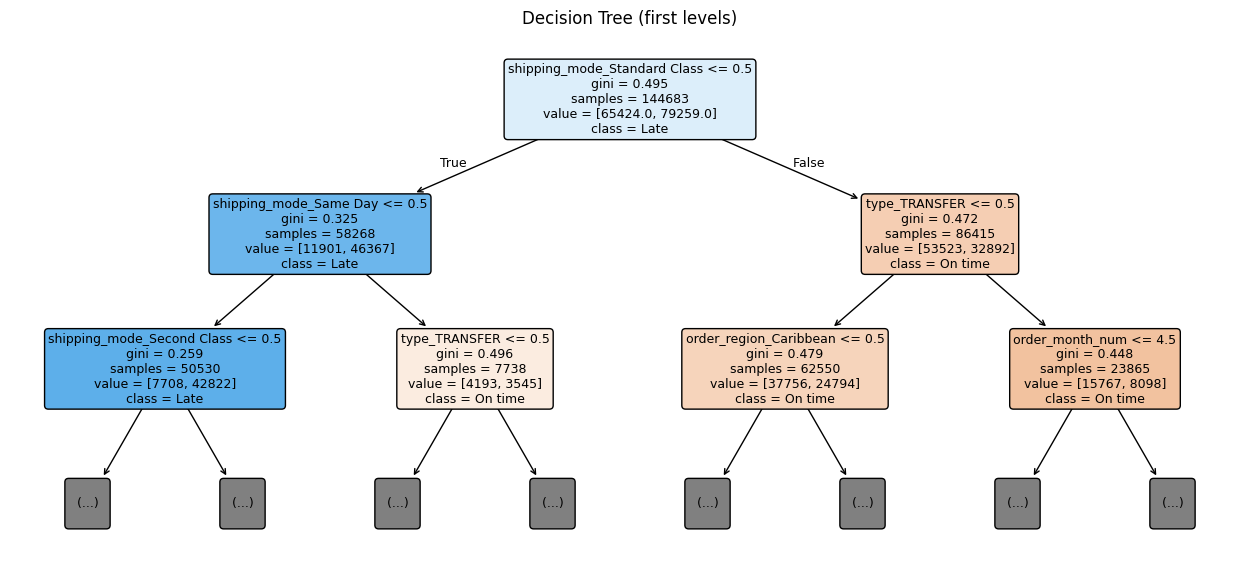

In [88]:
plt.figure(figsize=(16, 7))
plot_tree(dt, max_depth=2, feature_names=list(feature_names), class_names=["On time", "Late"],
          filled=True, rounded=True, fontsize=9)
plt.title("Decision Tree (first levels)")
plt.show()

**EN – Reading the tree:** Cross-validation chooses the shallowest tree in the grid (`max_depth` = 3, `min_samples_leaf` = 50). Deeper trees score lower (F1 macro 0.6835 at depth 12 with leaf size 50), which is a sign of overfitting. The rule of the tree is simple: **First Class and Second Class are predicted late, Same Day and Standard Class are predicted on time**. Payment type TRANSFER, the Caribbean region and the order month appear in the lower branches, but they do not change the predicted class. The three shipping mode variables hold about 99% of the feature importance.

**VI – Đọc cây quyết định:** Cross-validation chọn cây nông nhất trong lưới (`max_depth` = 3, `min_samples_leaf` = 50). Cây sâu hơn cho điểm thấp hơn (F1 macro 0.6835 ở độ sâu 12 với kích thước lá 50), đây là dấu hiệu overfitting. Luật của cây rất đơn giản: **First Class và Second Class được dự đoán trễ, Same Day và Standard Class được dự đoán đúng hạn**. Loại thanh toán TRANSFER, vùng Caribbean và tháng đặt hàng có xuất hiện ở các nhánh dưới nhưng không làm đổi nhãn dự đoán. Ba biến shipping mode chiếm khoảng 99% mức quan trọng.

# **Model Comparison**

In [89]:
comparison_clf = pd.DataFrame(results_clf).T.round(4).sort_values("F1 (macro)", ascending=False)
comparison_clf

,Accuracy,F1 (macro),Precision (Late),Recall (Late),ROC-AUC
Baseline 2 (shipping mode only),0.6969,0.6938,0.8542,0.5415,0.7299
Decision Tree,0.6969,0.6938,0.8542,0.5415,0.7375
Logistic Regression,0.6954,0.6927,0.8438,0.5477,0.7368
Baseline (majority class),0.5502,0.3549,0.5502,1.0000,0.5000


In [90]:
cv_shipping_only = cross_val_score(LogisticRegression(), Xtrain[:, sm_cols], ytrain,
                                   scoring="f1_macro", cv=gkf, groups=groups_train)

cv_table = pd.DataFrame({
    "CV F1 (macro) mean": [lr_fscore.mean(), dt_fscore.mean(), cv_shipping_only.mean()],
    "CV F1 (macro) std":  [lr_fscore.std(),  dt_fscore.std(),  cv_shipping_only.std()]
}, index=["Logistic Regression", "Decision Tree", "Baseline 2 (shipping mode only)"]).round(4)
cv_table.sort_values("CV F1 (macro) mean", ascending=False)

,CV F1 (macro) mean,CV F1 (macro) std
Decision Tree,0.6916,0.0064
Baseline 2 (shipping mode only),0.6916,0.0064
Logistic Regression,0.6913,0.0064


**EN – Discussion:**
- Every model is far better than the majority baseline (F1 macro 0.355).
- On the test set the results are almost identical: the Decision Tree and the shipping-mode-only baseline both reach 0.6938 and Logistic Regression reaches 0.6927. The difference (about 0.001) is too small to say that one is better.
- Cross-validation on the training set agrees: Decision Tree 0.6916, shipping mode only 0.6916, Logistic Regression 0.6913. The gap is much smaller than the variation between folds (`std` 0.0064), so they are tied.
- ROC-AUC is a little higher for the two models with all variables (Decision Tree 0.7375, Logistic Regression 0.7368) than for the shipping-mode-only baseline (0.7299). The other variables help slightly to rank orders by risk, but they barely change the predicted labels.
- **Main finding:** a model that uses only shipping mode is as good as the models that use all variables, which is consistent with the EDA.
- **Decision:** we choose **Logistic Regression** as the final model. It ties in performance with the Decision Tree and the baseline, uses all variables and shows the effect of each variable through its coefficients. The Decision Tree is kept as a confirmation, because its rules lead to the same conclusion.

**VI – Thảo luận:**
- Mọi model đều tốt hơn nhiều so với baseline majority (F1 macro 0.355).
- Trên tập test, kết quả gần như giống nhau: Decision Tree và baseline chỉ dùng shipping mode cùng đạt 0.6938, Logistic Regression đạt 0.6927. Chênh lệch (khoảng 0.001) quá nhỏ để nói model nào tốt hơn.
- Cross-validation trên tập train cho kết quả tương tự: Decision Tree 0.6916, chỉ shipping mode 0.6916, Logistic Regression 0.6913. Khoảng cách nhỏ hơn nhiều so với mức dao động giữa các fold (`std` 0.0064), nên các model này hòa nhau.
- ROC-AUC của hai model dùng đủ biến (Decision Tree 0.7375, Logistic Regression 0.7368) cao hơn một chút so với baseline chỉ dùng shipping mode (0.7299). Các biến còn lại giúp xếp hạng rủi ro tốt hơn một chút nhưng gần như không đổi nhãn dự đoán.
- **Phát hiện chính:** model chỉ dùng shipping mode tốt ngang các model dùng đủ biến, khớp với kết quả EDA.
- **Quyết định:** chọn **Logistic Regression** làm model cuối. Nó hòa về hiệu quả với Decision Tree và baseline, dùng đủ các biến và cho thấy tác động của từng biến qua hệ số. Decision Tree được giữ để xác nhận, vì các luật của cây dẫn đến cùng kết luận.

# **Final Model**

In [91]:
final_model = lr
y_pred_final = final_model.predict(Xtest)

print(classification_report(ytest, y_pred_final, digits=4))
print("Confusion Matrix:")
print(confusion_matrix(ytest, y_pred_final))

              precision    recall  f1-score   support

           0     0.6129    0.8760    0.7212     16118
           1     0.8438    0.5477    0.6643     19718

    accuracy                         0.6954     35836
   macro avg     0.7283    0.7119    0.6927     35836
weighted avg     0.7399    0.6954    0.6899     35836

Confusion Matrix:
[[14119  1999]
 [ 8918 10800]]


**EN – Reading the result on the test set (35,836 order items):** accuracy 0.695 and F1 macro 0.693.
- For **on-time items** the model recognises them well: 14,119 of 16,118 are correct (recall 0.88).
- For **late items** the model is reliable when it raises an alarm: when it says "late", it is right 84% of the time (precision 0.84). But it finds only 55% of the late items (recall 0.55): 10,800 are found and **8,918 are missed**. It gives 1,999 false alarms.
- In short: the model is a *conservative* alarm. It is useful to flag high-risk orders, but it cannot be used to catch all late orders. A probability threshold lower than 0.5 would find more late orders but give more false alarms (not tested here).

**VI – Đọc kết quả trên tập test (35,836 dòng):** accuracy 0.695 và F1 macro 0.693.
- Với **dòng đúng hạn**, model nhận ra khá tốt: đúng 14,119 trên 16,118 dòng (recall 0.88).
- Với **dòng trễ**, model đáng tin khi đã báo động: khi nói "trễ" thì đúng 84% (precision 0.84). Nhưng chỉ tìm được 55% số dòng trễ (recall 0.55): tìm đúng 10,800 dòng và **bỏ sót 8,918 dòng**. Có 1,999 báo động nhầm.
- Tóm lại: model là một bộ báo động *thận trọng*. Nó hữu ích để đánh dấu các đơn rủi ro cao, nhưng không thể dùng để bắt hết đơn trễ. Dùng ngưỡng xác suất thấp hơn 0.5 sẽ tìm được nhiều đơn trễ hơn nhưng tăng báo động nhầm (chưa thử ở đây).

In [92]:
print(classification_report(ytest, dt.predict(X_tree_test), digits=4))
print("Confusion Matrix:")
print(confusion_matrix(ytest, dt.predict(X_tree_test)))

              precision    recall  f1-score   support

           0     0.6126    0.8870    0.7247     16118
           1     0.8542    0.5415    0.6629     19718

    accuracy                         0.6969     35836
   macro avg     0.7334    0.7142    0.6938     35836
weighted avg     0.7456    0.6969    0.6907     35836

Confusion Matrix:
[[14296  1822]
 [ 9040 10678]]


**EN – Reading the Decision Tree on the same test set:** accuracy 0.697 and F1 macro 0.694. It finds 10,678 of the 19,718 late items (recall 0.54), misses 9,040 and gives 1,822 false alarms (precision 0.85). Compared with Logistic Regression it gives fewer false alarms but misses slightly more late items. Its predicted labels are the same as those of the shipping-mode-only baseline.

**VI – Đọc kết quả của Decision Tree trên cùng tập test:** accuracy 0.697 và F1 macro 0.694. Cây tìm đúng 10,678 trong 19,718 dòng trễ (recall 0.54), bỏ sót 9,040 dòng và có 1,822 báo động nhầm (precision 0.85). So với Logistic Regression, cây báo động nhầm ít hơn nhưng bỏ sót nhiều hơn một chút. Nhãn dự đoán của cây trùng với baseline chỉ dùng shipping mode.

In [93]:
coef = pd.Series(lr.coef_[0], index=feature_names).sort_values(key=abs, ascending=False)
coef.head(10)

,0
shipping_mode_First Class,0.676744
shipping_mode_Standard Class,-0.423643
days_for_shipment_scheduled,-0.362931
shipping_mode_Same Day,-0.359176
type_TRANSFER,-0.144687
shipping_mode_Second Class,0.110999
type_PAYMENT,0.065634
type_DEBIT,0.059654
type_CASH,0.025689
order_region_Canada,-0.025434


**EN:** These are the 10 largest coefficients of the Logistic Regression. A **positive** coefficient raises the predicted probability of a late delivery, a **negative** one lowers it. Because the variables were standardised, the sizes of the coefficients can be compared with each other.
- The four largest coefficients all belong to shipping mode and scheduled shipping days (between 0.36 and 0.68 in absolute value): First Class raises the risk (+0.68), while Standard Class (-0.42), scheduled shipping days (-0.36) and Same Day (-0.36) lower it.
- All the remaining coefficients are 0.14 or smaller in absolute value (for example payment type TRANSFER -0.14, shipping mode Second Class +0.11, other payment types and the Canada region below 0.07). This confirms that the model relies almost entirely on shipping mode.
- Shipping mode and scheduled days carry the same information, so their coefficients should be read together, not one by one (the negative sign of scheduled days should not be interpreted on its own).

**VI:** Đây là 10 hệ số lớn nhất của Logistic Regression. Hệ số **dương** làm tăng xác suất dự đoán giao trễ, hệ số **âm** làm giảm. Vì các biến đã được chuẩn hóa nên có thể so sánh độ lớn của các hệ số với nhau.
- Bốn hệ số lớn nhất đều thuộc về shipping mode và số ngày giao dự kiến (độ lớn từ 0.36 đến 0.68): First Class làm tăng rủi ro (+0.68), trong khi Standard Class (-0.42), số ngày giao dự kiến (-0.36) và Same Day (-0.36) làm giảm.
- Các hệ số còn lại đều có độ lớn từ 0.14 trở xuống (ví dụ loại thanh toán TRANSFER -0.14, shipping mode Second Class +0.11, các loại thanh toán khác và vùng Canada dưới 0.07). Điều này xác nhận model gần như chỉ dựa vào shipping mode.
- Shipping mode và số ngày giao dự kiến mang cùng một thông tin, nên cần đọc các hệ số của chúng cùng nhau, không đọc riêng từng cái (không nên diễn giải dấu âm của số ngày giao dự kiến một mình).

# Conclusion and Limitations / Kết luận và hạn chế

**EN – Conclusion:** The risk of a late delivery can be predicted moderately well from information known when the order is placed. Logistic Regression and the Decision Tree reach F1 macro about 0.69 and ROC-AUC about 0.74, much better than the 0.355 of the majority baseline. However, almost all the predictive power comes from **shipping mode**, which is the same as the promised delivery time. A rule that uses shipping mode alone performs just as well, and a deeper tree does not improve the result. For the business this means that reviewing the **promised delivery times** of the First Class and Second Class modes is likely to matter more than building a more complex model.

**VI – Kết luận:** Rủi ro giao trễ có thể dự đoán ở mức khá từ các thông tin biết lúc đặt hàng. Logistic Regression và Decision Tree đạt F1 macro khoảng 0.69 và ROC-AUC khoảng 0.74, tốt hơn nhiều so với 0.355 của baseline majority. Tuy nhiên gần như toàn bộ sức dự đoán đến từ **shipping mode**, cũng chính là thời gian giao đã hứa. Một luật chỉ dùng shipping mode cho kết quả tương đương, và cây sâu hơn không cải thiện kết quả. Với doanh nghiệp, điều này cho thấy việc xem lại **thời gian giao hứa** của First Class và Second Class có thể quan trọng hơn việc xây model phức tạp hơn.

**EN – Limitations:**
- Because of limited computing resources, this study used two simple models and did not test or tune more complex methods such as ensemble models and deep neural networks.
- Logistic Regression used its default settings; only the depth and leaf size of the Decision Tree were tuned.
- Only one train/test split was used; cross-validation was applied inside the training set.
- The model uses information known at order time. It estimates risk; it does not explain the causes of lateness.
- The data cover the full period (January 2015 to January 2018). From October 2017 the order pattern changes (about one item per order and few products), so these months may behave differently from the earlier period.

**VI – Hạn chế:**
- Do hạn chế về tài nguyên tính toán, bài chỉ dùng hai model đơn giản và không thử hoặc tinh chỉnh các phương pháp phức tạp hơn như ensemble model và mạng nơ-ron sâu.
- Logistic Regression dùng cấu hình mặc định; chỉ độ sâu và kích thước lá của Decision Tree được tune.
- Chỉ dùng một lần chia train/test; cross-validation được thực hiện trong tập train.
- Model dùng thông tin biết lúc đặt hàng. Nó ước lượng rủi ro, không giải thích nguyên nhân gây trễ.
- Dữ liệu bao gồm toàn bộ giai đoạn (01/2015 đến 01/2018). Từ tháng 10/2017 mô hình đơn hàng thay đổi (khoảng một mặt hàng mỗi đơn và ít sản phẩm), nên các tháng này có thể khác với giai đoạn trước.

# **Citing this Notebook**

If you use this notebook in your work, please cite it as follows:

Huyen, P.(2026).Graduation Thesis - Supply Chain Analytics.(Version 1.0.0). URL: https://github.com/huyentpham/BUS-450